In [6]:
# Importing all needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

sns.set_style("whitegrid")

In [7]:
# Loading the Dataset
df = pd.read_csv("Titanic-Dataset.csv")   

print("Shape:", df.shape)
df.head()

Shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [8]:
df.info()  # gathering more info about the data frame such as the datatypes 

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


In [9]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [10]:
# Include text columns too
df.describe(include="object")

,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,B96 B98,S
freq,1,577,7,4,644


In [11]:
# Checking for missing values in the dataset
missing = df.isnull().sum()
missing_pct = (df.isnull().mean() * 100).round(2)
pd.DataFrame({"Missing": missing, "Percent": missing_pct})[missing > 0]

,Missing,Percent
Age,177,19.87
Cabin,687,77.10
Embarked,2,0.22


In [12]:
# Keep a copy of the original Age for the before/after plot
original_age = df["Age"].copy()

# 1. Age (numeric, 20% missing) -> median imputation
age_median = df["Age"].median()
df["Age"] = df["Age"].fillna(age_median)

# 2. Embarked (categorical, only 2 missing) -> fill with the most frequent value (mode)
embarked_mode = df["Embarked"].mode()[0]
df["Embarked"] = df["Embarked"].fillna(embarked_mode)

# 3. Cabin (77% missing) -> too sparse to impute, so drop it
df = df.drop(columns=["Cabin"])

print("Age median used:", age_median)
print("Embarked mode used:", embarked_mode)
print("\nRemaining missing values:\n", df.isnull().sum())

Age median used: 28.0
Embarked mode used: S

Remaining missing values:
 PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [13]:
# PassengerId is just an index. Name and Ticket are unique text identifiers.
df = df.drop(columns=["PassengerId", "Name", "Ticket"])
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked
0,0,3,male,22.0,1,0,7.2500,S
1,1,1,female,38.0,1,0,71.2833,C
2,1,3,female,26.0,0,0,7.9250,S
3,1,1,female,35.0,1,0,53.1000,S
4,0,3,male,35.0,0,0,8.0500,S


In [14]:
# Encoding categorical columns like "Sex"
le = LabelEncoder()
df["Sex"] = le.fit_transform(df["Sex"])

print("Mapping:", dict(zip(le.classes_, le.transform(le.classes_))))
df[["Sex"]].head()

Mapping: {'female': np.int64(0), 'male': np.int64(1)}


,Sex
0,1
1,0
2,0
3,0
4,1


In [15]:
# Encode 'Embarked' using onehotencoder
ohe = OneHotEncoder(sparse_output=False, dtype=int)   # on older sklearn (<1.2) use sparse=False
embarked_encoded = ohe.fit_transform(df[["Embarked"]])

embarked_df = pd.DataFrame(
    embarked_encoded,
    columns=ohe.get_feature_names_out(["Embarked"]),
    index=df.index
)

# Replace the original Embarked column with the new one-hot columns
df = pd.concat([df.drop(columns=["Embarked"]), embarked_df], axis=1)
df.head()

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_C,Embarked_Q,Embarked_S
0,0,3,1,22.0,1,0,7.2500,0,0,1
1,1,1,0,38.0,1,0,71.2833,1,0,0
2,1,3,0,26.0,0,0,7.9250,0,0,1
3,1,1,0,35.0,1,0,53.1000,0,0,1
4,0,3,1,35.0,0,0,8.0500,0,0,1


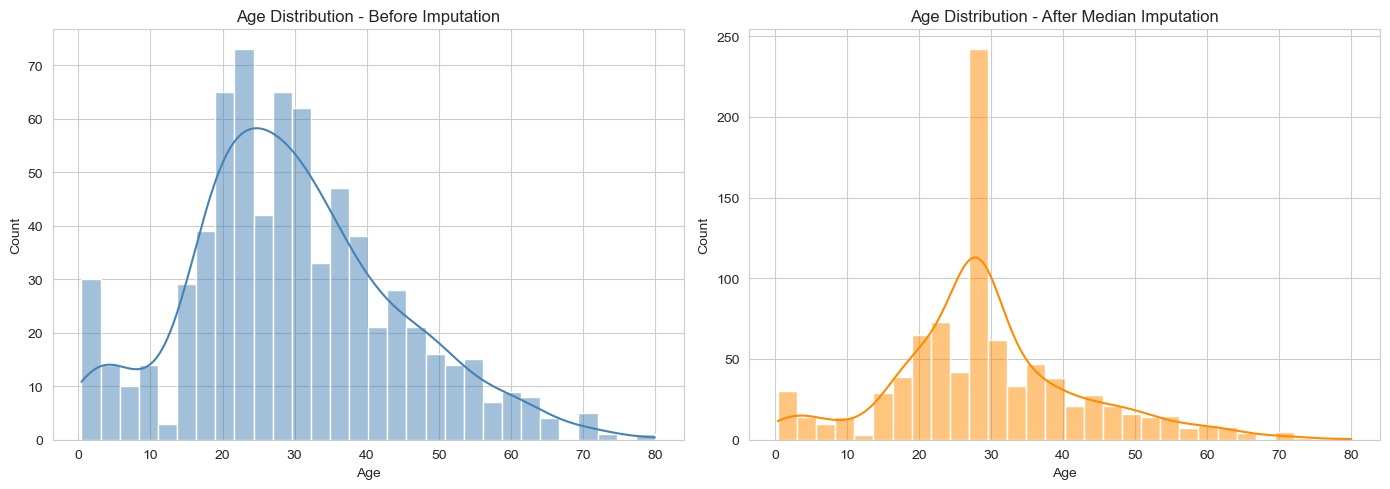

In [16]:
# Visualizing the age distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Before imputation (missing values ignored)
sns.histplot(original_age.dropna(), bins=30, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Age Distribution - Before Imputation")
axes[0].set_xlabel("Age")

# After imputation
sns.histplot(df["Age"], bins=30, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("Age Distribution - After Median Imputation")
axes[1].set_xlabel("Age")

plt.tight_layout()
plt.show()

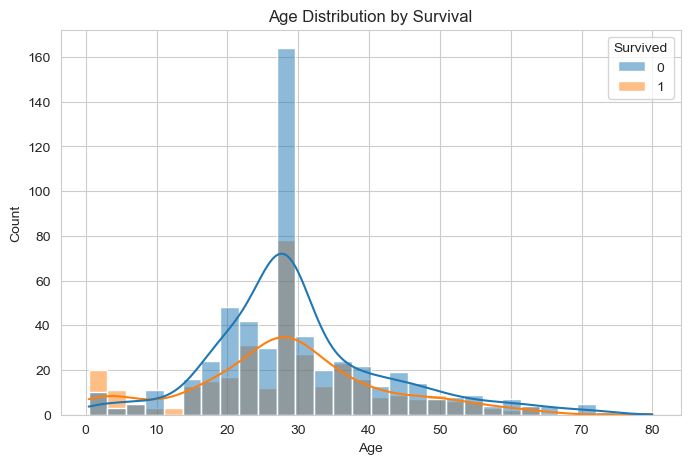

In [17]:
# Bonus: age distribution by survival
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="Age", hue="Survived", bins=30, kde=True, multiple="layer")
plt.title("Age Distribution by Survival")
plt.show()

In [18]:
# Finally checking and saving the cleaned csv
print("Missing values left:", df.isnull().sum().sum())
print("Final shape:", df.shape)
df.info()

Missing values left: 0
Final shape: (891, 10)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Survived    891 non-null    int64  
 1   Pclass      891 non-null    int64  
 2   Sex         891 non-null    int64  
 3   Age         891 non-null    float64
 4   SibSp       891 non-null    int64  
 5   Parch       891 non-null    int64  
 6   Fare        891 non-null    float64
 7   Embarked_C  891 non-null    int64  
 8   Embarked_Q  891 non-null    int64  
 9   Embarked_S  891 non-null    int64  
dtypes: float64(2), int64(8)
memory usage: 69.7 KB


In [19]:
df.to_csv("titanic_cleaned.csv", index=False)
print("Saved as titanic_cleaned.csv")

Saved as titanic_cleaned.csv
